In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
from pathlib import Path

In [2]:
ruta = Path("data/processed")
entrada = ruta / "SPY_2015_2025_targets.csv" 
salida = Path("results/semana_09") #directorio
salida.mkdir(parents=True, exist_ok=True) #crea la carpeta

if not entrada.exists():
   raise FileNotFoundError(entrada)
 
datos = pd.read_csv(entrada, index_col=0, parse_dates=True) #lee el archivo estableciedno la 1era columna como indice de fecha
  
assert isinstance(datos.index, pd.DatetimeIndex) #verifica que el indice se temporal
assert not datos.index.isna().any() #verifica que no tenga fechs nulas 
assert datos.index.is_unique # verficica que no tenga fechas duplicadas
assert datos.index.is_monotonic_increasing    #comprueba que este ordenado en forma cronlogica ascendente 
necesarias = ["Return", "Vol_5", "Vol_10", "Vol_20", "Vol_30", "Target_Vol_5"]
faltantes = [c for c in necesarias # verifica las columnas obligatorias y la presencia exacta de return, etc. 
              if c not in datos.columns]
assert not faltantes, f"Faltan columnas: {faltantes}"
assert len(datos) > 100 #confirma que haya mas de 100 observaciones 
assert np.isfinite(datos["Return"]).all()
for c in necesarias[1:]:
     s = datos[c].dropna()
     assert len(s) > 0
     assert np.isfinite(s).all() #verifica que no exista valores finitos erroneos ni volatilidad negativa
     assert (s >= 0).all() 
print(datos.shape, datos.index.min(), datos.index.max())

(2765, 43) 2015-01-05 00:00:00 2025-12-31 00:00:00


Imprime las dimensiones del dataframe  junto con la primera y la ultima fecha cargada. 

In [3]:
#Queremos obervar que la variable target_5 esté alineada en el tiempo y no contenga distorsiones. 
h = 5
objetivo = "Target_Vol_5" #extraemos la variable
y = datos[objetivo]
assert y.iloc[-h:].isna().all() #verifica que los ultimos registros sean obligatoriamente NaN
assert y.iloc[:-h].notna().all() #Toda las filas anteriores a los ultimos 5 registros contegan datos validos
assert y.isna().sum() == h #El numero total de nulos en la columna sea igual a 5 

esperado = (datos["Return"].rolling(h).std(ddof=1).shift(-h)) #reconstruye la varible esperada aplicandolo.
np.testing.assert_allclose( y.to_numpy(), esperado.to_numpy(), # Compara punto por punto la variable del CSV contra el realculo usado 
rtol=1e-7, atol=1e-10, equal_nan=True) #define una tolerancia relativa de 10^-7 

Si todas las pruebas pasan entonces que da matematicamente demostrado que no existe desfases temporales ni errores en la definicon del objetivo

In [4]:
#Generamos las 7 series de pronostico de volatilidad futura de 5 dias 
pred = pd.DataFrame(index=datos.index) # crea un dataframe indexando las misma fechas originales
for w in [5, 10, 20, 30]: pred[f"HV{w}"] = datos[f"Vol_{w}"] #para la ventanas asigna las columnas existentes
for k in [5, 10, 20]:pred[f"MA{k}"] = (datos["Vol_5"].rolling(k, min_periods=k).mean()) # para la volatilidad media calcula el promedio de los 5 dias de los ultimos k dias
modelos = pred.columns.tolist() #extrae la lista con los nombres de todas las columnas de DF de prediciones
assert not any("Target" in c for c in modelos) #recorre cada nombre de columna y devuelve TRUE si encuentra la palabra TARGET en alguna d ellas 
for c in modelos: #verifica que esa codicion sea falsa
   assert np.isfinite(pred[c].dropna()).all() 
   assert (pred[c].dropna() >= 0).all() # verifica que los valores generados sean finitos y no negativos 

Crea las 7 columnas de predccion: HV5, HV10, HV20, HV30 Y MA20.

In [5]:
#Hacemos una comprobacion manual en una posicion especifica, es decir, realiza una auditoria para confrimas que las funciones de
#ventana movil generadas en celdas previas coinciden con la teoria 
#VOLATILIDAD HISTORICA
i = 80
for w in [5, 10, 20, 30]: #iteramos sobre las 4 ventanas retrospectivas 
  ventana = datos["Return"].iloc[i-w+1:i+1] #extrae los rendimientos historicos pasados exactamnete desde la posicion i-w+1 hasta i 
  assert len(ventana) == w #comprueba que la ventana cortada contenga w datos
  np.testing.assert_allclose(pred[f"HV{w}"].iloc[i], ventana.std(ddof=1), rtol=1e-7, atol=1e-10) #calcula la desviacion estandar muestral
#sobre los rendimientos de la ventana y valida que coincida hasta con 10 deciamales con la predicion en PRED
#MEDIA MOVIL DE LA VOLATILIDAD 
for k in [5, 10, 20]: #iteramos sobre los 3 periodos
   ventana = datos["Vol_5"].iloc[i-k+1:i+1]  #extrae los ultimos k valores calculados de la columna
   assert len(ventana) == k ##confirma que el tamaño de la ventana sea igual a k 
   assert ventana.notna().all() #asegura que no existan valores nulos en la ventana extraida
   np.testing.assert_allclose( pred[f"MA{k}"].iloc[i], ventana.mean(),rtol=1e-7, atol=1e-10) #obtiene el promedio aritmetico simple de
#lo k valores de Vol_5 y comprueba que coincida de forma exacta con la prediccion.  

Confirma con precision decimal que las funciones estructurales en la seccion 10 reproducen exactamente la logica teorica sisn sesgos de ajustes

In [6]:
#Prepara la matriz de datos completa y elimina los registros no evaluables para garantizar que todos los modelos se midann sobre las mismas fechas exactas
base = pd.concat([datos[[objetivo]], pred], axis=1) #une horizontalmente la columna objetivo con las 7 columnas de predicciones en un unico df
print(base.isna().sum()) #da valores nulos 
valida = base.notna().all(axis=1) # da mascara booleana que marca unicamente filas donde las columnas tiene datos numericos
pos = np.flatnonzero(valida.to_numpy()) # obtiene posiciones numericas enteras de los trigstros True
assert len(pos) > 100 #asegura que existan mas de 100 observaciones
assert np.all(np.diff(pos) == 1), ("Hay huecos interiores: revisar antes de continuar") #verifica que las diferencias sean exactamnete 1, para que no haya saltos o fechas faltantes
comun = base.loc[valida].copy() #deja solo la muestra valida
assert np.isfinite(comun.to_numpy()).all() #verifica que no trnga valores infinitos o faltantes
assert comun.index.is_unique #  #confirma que el indice de fechas no tenga repetidos y esten en oden cronologico ascendente
assert comun.index.is_monotonic_increasing
print("Muestra comun:", len(comun)) #imprime el total de dias evaluados 
print(comun.index.min(), comun.index.max()) #da la primera y ultima fecha

Target_Vol_5     5
HV5              4
HV10             9
HV20            19
HV30            29
MA5              8
MA10            13
MA20            23
dtype: int64
Muestra comun: 2731
2015-02-17 00:00:00 2025-12-23 00:00:00


Aplica un filtro para evitar que el objetivo TARGET_VOL_5 contamine el periodo de prueba con datos de futuro, es decir que haya fuga de informacion en la frontera

In [7]:
fin_objetivo = pd.Series(datos.index, index=datos.index) #crea una serie donde se almacena su propia fecha de origen t
fin_objetivo = fin_objetivo.shift(-h) #desplaza las fechas h=5 posiciones hacia atras, para cualquier fecha t, finobjetivo guarda la fecha exacta en la que trmina
corte = int(np.floor(0.70 * len(comun))) #calcula la posicion numerica que representa el 70% inicial de la muestra
fecha_inicio = comun.index[corte]#obtiene la fecha exacta donde inicia el periodo de evalucaion
inicial = comun.iloc[:corte].copy() #toma las primeras filas que corresponden al 70% inicial
mascara = fin_objetivo.reindex(inicial.index) < fecha_inicio #genera una condicion boolena que verifica si la fecha final del objetivo ocurrio antes de que la evalucaion iniciara
desarrollo = inicial.loc[mascara].copy() #excluye del bloque de desarrollo las filas cuyos objetivos en 5 dias alcanzaban a tocar o entrar en periodo de evalucion
evaluacion = comun.iloc[corte:].copy() #asigna el 30% restante de la muestra comun al bloque de evalucion preliminar
assert len(desarrollo) > 0 and len(evaluacion) > 0 #garantiza que ambos bloques contengan datos
assert (fin_objetivo.loc[desarrollo.index] < fecha_inicio).all() #comprueba que ninguna observacion contenga rendimiento dentro del periodo de evalucion
assert desarrollo.index.max() < evaluacion.index.min()#confrima el estricto orden cronologico entre el final de desarrollo y el inicio de la evalucion
print("Desarrollo:", len(desarrollo))
print("Filas excluidas en frontera:",
len(inicial) - len(desarrollo))
print("Evaluacion:", len(evaluacion))

Desarrollo: 1906
Filas excluidas en frontera: 5
Evaluacion: 820


In [8]:
def metricas(y, p):
  y = np.asarray(y, dtype=float) #convierte la serie del valor observado y y del pronostico p en arreglos de np con formato numerico
  p = np.asarray(p, dtype=float)
  assert len(y) == len(p) and len(y) > 0 #verifica que ambos arreglos tengan la misma longitud y contengan al menos un dato
  assert np.isfinite(y).all() and np.isfinite(p).all() #comprueba que no tenga valores nulos ni infinitos
  e = y - p #calcula el vector de errores de predicion
  mape = (100 * np.mean(np.abs(e / y)) #calcula el error procentual absoluto medio, si existe al menos un valor y=0 asigna NAN para evitar divisiones entre cero
  if np.all(y > 0) else np.nan) 
  return {"N": len(y), #devuelve un diccionario de las siguientes metricas
     "MAE": np.mean(np.abs(e)), #erro absoluto medio
     "RMSE": np.sqrt(np.mean(e**2)), #raiz del error cuadratico medio
     "Sesgo": np.mean(e), #promedio simple del error, valor negativo indica que el modelo sobreestima la volatilidad real, positivo indica subestimacion
     "MAPE_pct": mape, #porcentaje promedio de desviacion estandar
     "Objetivos_cero": int(np.sum(y == 0))} #conteo de dias donde la volatilidad fue cero
#Evalua los 7 modelos y construye una tabla
filas = []
for m in modelos: #recorre cada uno de los 7 modelos
  fila = metricas(evaluacion[objetivo], evaluacion[m]) #evalua los valores reales contra las predicciones del modelo actual
  filas.append({"Modelo": m, **fila})#agrega a diccionario el resultado a la lista
tabla = pd.DataFrame(filas).set_index("Modelo") #convierte en un df utulizando el nombre del modelo como indice
assert tabla["N"].nunique() == 1 #verifica que los modelos se hayan evaluado exactamnete sobre el mismo numero de observaciones
assert (tabla["RMSE"] + 1e-12 >= tabla["MAE"]).all() #garantiza la propiedad matematica con un margen de 10^-12
rmse_ref = tabla.loc["HV5", "RMSE"]#extrae el RMSE del modelo base principal para usarlo como referencia
tabla["Mejora_RMSE_pct_vs_HV5"] = ( 100 * (1 - tabla["RMSE"] / rmse_ref) #calcula el porcentaje de mejora relativa de RMSE respecto a HV5: positivo representa una reduccion en el error cuadratico
     if rmse_ref > 0 else np.nan)
print(tabla.sort_values("RMSE"))

          N       MAE      RMSE     Sesgo   MAPE_pct  Objetivos_cero  \
Modelo                                                                 
MA20    820  0.003427  0.005771 -0.000168  47.887697               0   
HV20    820  0.003589  0.006001 -0.000702  51.878193               0   
HV30    820  0.003683  0.006010 -0.000842  54.452087               0   
MA10    820  0.003547  0.006062 -0.000115  48.631070               0   
HV10    820  0.003689  0.006102 -0.000426  51.402582               0   
MA5     820  0.003741  0.006206 -0.000088  49.721446               0   
HV5     820  0.003933  0.006328 -0.000051  53.108692               0   

        Mejora_RMSE_pct_vs_HV5  
Modelo                          
MA20                  8.808171  
HV20                  5.167406  
HV30                  5.024387  
MA10                  4.213487  
HV10                  3.580844  
MA5                   1.930206  
HV5                   0.000000  


Todos los modelos se evaluaron 820 valores, presenta el RMSEmas bajo de la muestra y el menor MAE lo que indica que suavisar la volatilidad a 5 dias con una ventana  de 20 periodos reduce el impacto del ruido y las oscilaciones extremas, se muestra un sesgo negativo en todos lo que significa que los modelos base tienden a sobrestimar levemente la volatilidad real futura en ste periodo de prueba

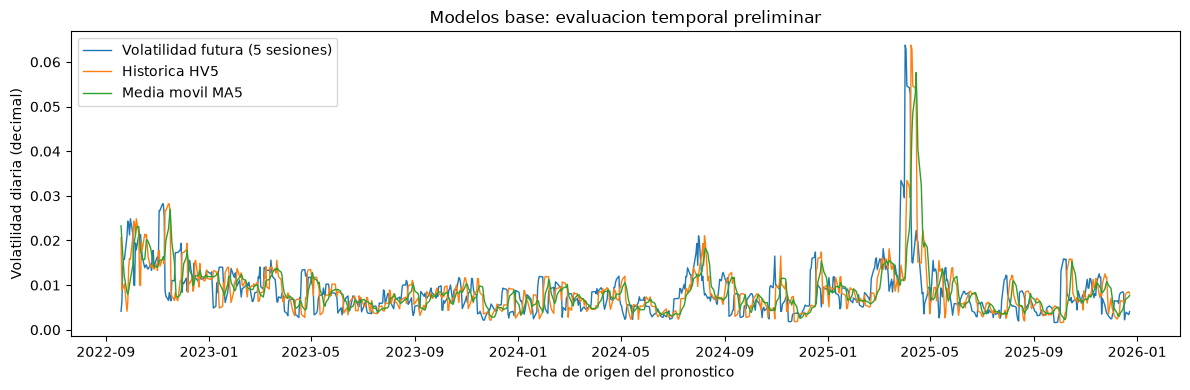

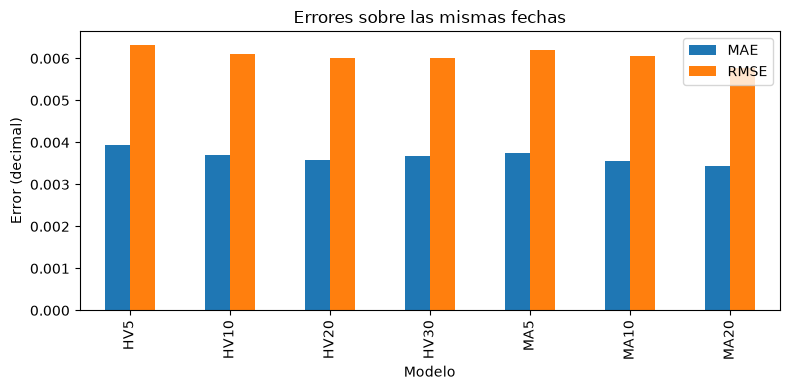

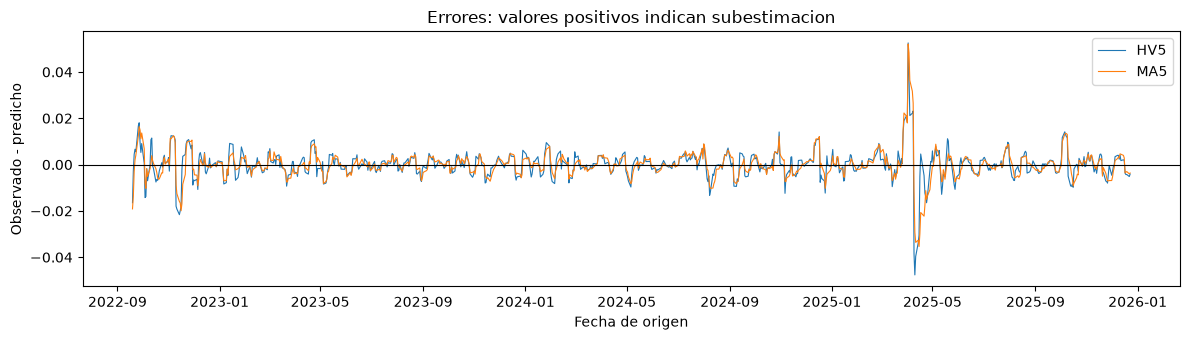

In [9]:
#GRAFICA 1
#Serie temporal de volatilidad observada vs predicha
fig, ax = plt.subplots(figsize=(12, 4))
for c, etiqueta in [(objetivo, "Volatilidad futura (5 sesiones)"), ("HV5", "Historica HV5"), #recorre las 3 columnas: vola real futura, la persistencia simple y la media movil
   ("MA5", "Media movil MA5")]:
   ax.plot(evaluacion.index, evaluacion[c], label=etiqueta, linewidth=1) #grafica las 3 en funcion del tiempo
ax.set(xlabel="Fecha de origen del pronostico",
ylabel="Volatilidad diaria (decimal)",
title="Modelos base: evaluacion temporal preliminar")
ax.legend()
fig.tight_layout()
fig.savefig(salida / "01_observado_predicho.png", dpi=180) #Gurda la imagen en alta resolucion en la carpeta de resultados
plt.show()

#GRAFICA 2
#Comparativa de metricas de error por modelo 
fig, ax = plt.subplots(figsize=(8, 4))
tabla[["MAE", "RMSE"]].plot.bar(ax=ax) #genera un grafico de barras agrupadas
ax.set(ylabel="Error (decimal)", xlabel="Modelo",
title="Errores sobre las mismas fechas")
fig.tight_layout()
fig.savefig(salida / "02_metricas.png", dpi=180)
plt.show()

#GRAFICA 3
fig, ax = plt.subplots(figsize=(12, 3.5))
for m in ["HV5", "MA5"]:
 error = evaluacion[objetivo] - evaluacion[m]
 ax.plot(error.index, error, label=m, linewidth=0.8)
ax.axhline(0, color="black", linewidth=0.8)
ax.set(xlabel="Fecha de origen", ylabel="Observado - predicho",
title="Errores: valores positivos indican subestimacion")
ax.legend()
fig.tight_layout()
fig.savefig(salida / "03_errores.png", dpi=180)
plt.show()

GRAFICA 1  
Muestra la evolucion temporal desde finales de 2022 hasta inicios de 2026, tanto HV5 y MA5 siguen la tendencia general de la volatilidad, en donde en eventos de alta volatilidad, como el pico de inicios del 2025 donde la volatilidad diaria supera el 0.06, responden con retraso porque dependen del pasado, MA5 presenta una curva ligeramnete mas suave que HV5 reduciendo variaciones extremas de un solo dia.  
GRAFICA 2  
RMSE > MAE, en los 7 modelos se cumple qie la barra de RMSE es mas alta, la cual es consistente al penalizar cudraticamnete los errores de mayor magnitud. A medida que aumenta el tamaño de la ventana, las barras tienden a reducirse levemente.   
GRAFICA 3  
Durante los peridos de baja volatilidad (2023 y 2024) los errores se mantienen oscilando muy cerca de la linea cero. A princiios de 2025 se observa un pico positivo agudo, ocurre debido a que el mercado sufrio un choque repentino que el modelo historico no pudo prever. Inmediatamnete depsues del pico el error pasa a ser negativo ya que la ventana historica mantiene inflado el pronostico cuando el mercado ya regreso a la calma.

In [10]:
base.to_csv(salida / "SPY_2015_2025_modelos_base.csv") #exporta el dataset completo que contiene las 7 columnas y las 7 series de pronostico
evaluacion.to_csv(salida / "muestra_evaluacion.csv") #guarda exclusivamente las 820 observaciones correspondinetes al bloque de evaluacion 30% utilizada par medir los errores
tabla.to_csv(salida / "metricas_modelos_base.csv") #exporta la tabla comparativa de desempeño (MAE, RMSE, SESGO, MAPE_pct, etc)
periodos = pd.DataFrame([{"Bloque": "desarrollo", "N": len(desarrollo),"Inicio": desarrollo.index.min(), #contruye una tabla resumen con la infromacion estrcutural 
"Fin": desarrollo.index.max()},{"Bloque": "evaluacion_preliminar", "N": len(evaluacion),"Inicio": evaluacion.index.min(),  #fecha inicial
"Fin": evaluacion.index.max()}])  #fecha final 
periodos.to_csv(salida / "periodos.csv", index=False) #guarda dicha tabla de control en el archivo sin incluir el indice numerico por defecto
leida = pd.read_csv(salida / "muestra_evaluacion.csv", #reimporra a la memoria desde el disco el archivo recien guardado forzando la 1er columna como indice temóral
index_col=0, parse_dates=True)
assert leida.index.equals(evaluacion.index) #comprueba que el indice de fechas reimportado sea identico en orden y contenido al df origianl 
assert leida.columns.tolist() == evaluacion.columns.tolist() #confrima que los nombres y el orden de todas las columnas permanezcan intactos
np.testing.assert_allclose(leida.to_numpy(), evaluacion.to_numpy(),rtol=1e-7, atol=1e-10)#verifica que mingun valor numerico haya sufrido truncamiento o perdidas 

#### Conclusion

Se comprobo que el modelo MA20 obtuvo el menor de error en el bloque de prueba de N= 820 pbservaciones en el bloque de evaluacion preliminar (30% de la serie comun de 2731 datos), superando a la referencia base HV5, es decir, promediar 20 dias de volatilidad ayuda a filtrar de forma efectiva el ruido del mercado. Todos los modelos arrojaron un sesgo negativo, indicandoo una ligera sobreestimacion de la volatilidad real durante este periodo, asi mismo se confirmo visualmente que la principal limitacion de estas reglas historicas es el rezago, debido a que reaccion tarde ante picos o choques repentinos y tardan en ajustarse cuando el mercado regresa a la normalidad